# Project: Market Analysis with Python
### By Franchezka Huaranca & Jason Haß



As the data analysts team for the A-Z-Market online shop, the goal of this project is to analyze sales history data and identify key points that made the business profitable or not.

Before starting to look into the data, we will first install the packages needed for this project.


In [20]:
%matplotlib inline 
# ^-- we want to directly look at the created plots to build up on them

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

With the packages installed, we can dowload the given dataset.

In [21]:
dataset = pd.read_csv("sales.csv")

To get a first impression of what our data looks like, we will perform some basic commands.

In [22]:
dataset.head()

,Order ID,Order Date,Order Year,Order Quarter,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,CA-2018-152156,08/11/2018,2018,3,11/11/2018,Second Class,CG-12520,Claire Gute,Consumer,United States,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,CA-2018-152156,08/11/2018,2018,3,11/11/2018,Second Class,CG-12520,Claire Gute,Consumer,United States,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,CA-2018-138688,12/06/2018,2018,4,16/06/2018,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,US-2017-108966,11/10/2017,2017,4,18/10/2017,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,US-2017-108966,11/10/2017,2017,4,18/10/2017,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [23]:
dataset.tail()

,Order ID,Order Date,Order Year,Order Quarter,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9989,CA-2016-110422,21/01/2016,2016,1,23/01/2016,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,...,33180.0,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.248,3,0.2,4.1028
9990,CA-2019-121258,26/02/2019,2019,1,03/03/2019,Standard Class,DB-13060,Dave Brooks,Consumer,United States,...,92627.0,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,0.0,15.6332
9991,CA-2019-121258,26/02/2019,2019,1,03/03/2019,Standard Class,DB-13060,Dave Brooks,Consumer,United States,...,92627.0,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.576,2,0.2,19.3932
9992,CA-2019-121258,26/02/2019,2019,1,03/03/2019,Standard Class,DB-13060,Dave Brooks,Consumer,United States,...,92627.0,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,0.0,13.3200
9993,CA-2019-119914,04/05/2019,2019,2,09/05/2019,Second Class,CC-12220,Chris Cortes,Consumer,United States,...,92683.0,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.160,2,0.0,72.9480


#### Understanding the data

To understand the nature of the "Segment" column, we create a table including the Customer IDs and the Segments. Afterwards we group the customer ids by segment in order to see the total amount of orders per segment. We then look at the total amount of customers and compare them to the total amount of customer ids in the grouped table. 

Since both amount have the same number, we can be certain that the "Segment" is linked to Customers and not eg. the "Category".

In [5]:
category_test = dataset[["Customer ID","Segment"]]

category_test

,Customer ID,Segment
0,CG-12520,Consumer
1,CG-12520,Consumer
2,DV-13045,Corporate
3,SO-20335,Consumer
4,SO-20335,Consumer
...,...,...
9989,TB-21400,Consumer
9990,DB-13060,Consumer
9991,DB-13060,Consumer
9992,DB-13060,Consumer


In [24]:
category_test_group = category_test.groupby("Segment")["Customer ID"].count().reset_index()

category_test_group

,Segment,Customer ID
0,Consumer,5191
1,Corporate,3020
2,Home Office,1783


In [25]:
ncustomers = dataset["Customer ID"].count()

print(ncustomers)

9994


    
    
    
### Descriptive Analysis

In order to get a better understanding of the sales behaviour, we created multiple dataframes that group certain sales information. For instance, Region, Category etc. of our sales. We also take a first look, at the **average profit per item in that group**. That can give first hints on what might influence **profitability**.

Because we perform that simple but repetitive analysis, it saves time and code to create a function, that groups the sales by a given sales information and shows the average profit per item in that group. The function is defined in the following code.

##### **Function:**

In [26]:
def avg_profit_per_group(Group): 
    
    result = dataset.groupby(Group).agg(Orders = ("Order ID", "count"), Sum_Profit=("Profit", "sum"), Sum_Sales = ("Sales", "sum")).reset_index()
    
    result["Profit_Ratio"] = result["Sum_Profit"]/result["Sum_Sales"]
    
    return result

#### **Sales and Profit Ratio per Year**

In [27]:
sales_year = avg_profit_per_group("Order Year")
sales_year

,Order Year,Orders,Sum_Profit,Sum_Sales,Profit_Ratio
0,2016,1993,49543.9741,484247.4981,0.102311
1,2017,2102,61618.6037,470532.5090,0.130955
2,2018,2587,81795.1743,609205.5980,0.134265
3,2019,3312,93439.2696,733215.2552,0.127438


If we convert this table into a chart, we can find the following trend for the profit ratio over the years.

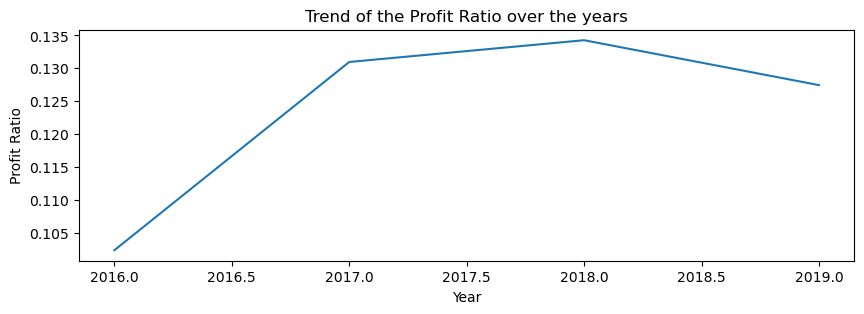

In [10]:
plt.figure(figsize = (10,3))
chart=sb.lineplot(data=sales_year, x="Order Year", y="Profit_Ratio")
chart.set_title("Trend of the Profit Ratio over the years")
chart.set_xlabel("Year")
chart.set_ylabel("Profit Ratio")
plt.show()

One important finding from the **profit ratio** or **profit margin** is that the company has become overall more profitable from 2016 to 2019, where the year with highest profit margin is 2018. However, it is recommendable action steps such as improving the operational efficiency for reducing costs, in order to return to a growing profit margin trend for the future.

# Profit Margin behaviour

There is a **slight difference** across the four years when it comes to the profit ratio per order. We can also see a **growing trend in sales numbers** over the four years. We will look further into the sales over time. Therefore, we create a new column, that indicates the month and year of an order in the mm.yyyy format.

In [28]:
dataset.dtypes #-> check for the type of our columns.


dataset["Order Date"] = pd.to_datetime(dataset["Order Date"], format="%d/%m/%Y")

# To be able to group by months, we create "Period" in a "M" format which deletes the days from our dates.
dataset["Period"] = dataset["Order Date"].dt.to_period('M')

#dataset.head(10) -> check the results

sales_months = avg_profit_per_group("Period")

sales_months.head()

,Period,Orders,Sum_Profit,Sum_Sales,Profit_Ratio
0,2016-01,79,2450.1907,14236.895,0.172101
1,2016-02,46,862.3084,4519.892,0.190781
2,2016-03,157,498.7299,55691.009,0.008955
3,2016-04,135,3488.8352,28295.345,0.123301
4,2016-05,122,2738.7096,23648.287,0.115810


To look for seasonal trends, we create a line plot with the sales over time. In order to plot the graph and create lines, we must convert the type of our "Period" to a normal time format. We hereby manipulate the dates so they all start with "01".


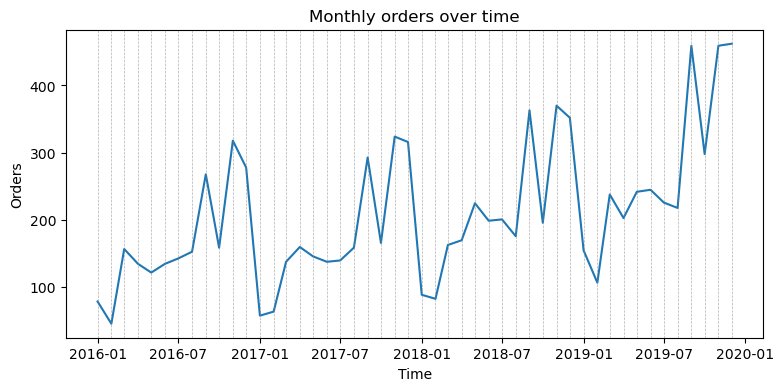

In [29]:
sales_months["Period_nt"] = sales_months["Period"].dt.to_timestamp()

plt.figure( figsize = (9, 4))
chart=sb.lineplot(data=sales_months, x='Period_nt', y='Orders')

for date in sales_months["Period_nt"]:
    plt.axvline(x=date, color="gray", linestyle="--", linewidth=0.5, alpha=0.6)

    
chart.set_title('Monthly orders over time')
chart.set_xlabel('Time')
chart.set_ylabel('Orders')

plt.show()

As another insight, we can see a **trend towards rising sales** over the given timespan as well as **strong seasonal effects**. Sales drop drastically in January and February. Sales peak in September and November with a drop in October. This is an important insight for the company, in order to predict an accurate forecast for the demand, based on the sales and the seasonality, and to increase the accuracy of the purchasing department.

We will now look at the profits to see if they match the sales behaviour.

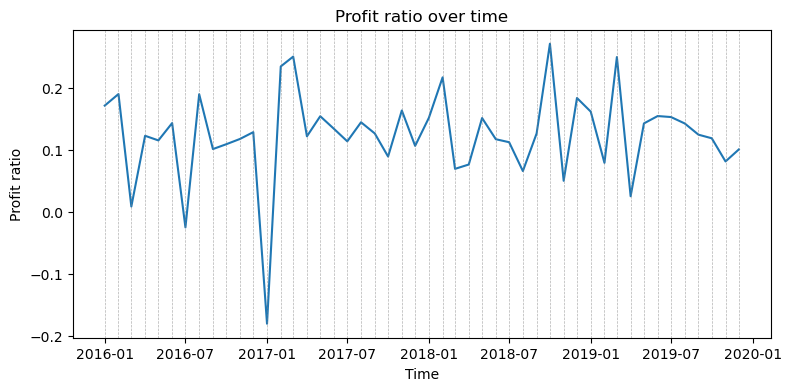

In [30]:
plt.figure( figsize = (9, 4))
chart=sb.lineplot(data=sales_months, x='Period_nt', y='Profit_Ratio')

for date in sales_months["Period_nt"]:
    plt.axvline(x=date, color="gray", linestyle="--", linewidth=0.5, alpha=0.6)

    
chart.set_title('Profit ratio over time')
chart.set_xlabel('Time')
chart.set_ylabel('Profit ratio')

plt.show()

The profit ratio does not follow our sales behaviour. There is **no visible trend** over time but an extrem **drop in January 2017**. To look for further connections regarding the extremes in sales/profit we will look at the discount strategy of our company.

#### **Discounts**

We create a new dataframe that gives us the percentage of orders per month that were given a discount on.

In [31]:
Disc_quota = (dataset.groupby("Period", as_index=False).agg(pct_discount_orders=("Discount", lambda x: (x > 0).mean() * 100)))

Disc_quota["Period_nt"] = Disc_quota["Period"].dt.to_timestamp()

Disc_quota.head()

,Period,pct_discount_orders,Period_nt
0,2016-01,35.443038,2016-01-01
1,2016-02,45.652174,2016-02-01
2,2016-03,59.235669,2016-03-01
3,2016-04,43.703704,2016-04-01
4,2016-05,51.639344,2016-05-01


We now create a line plot.

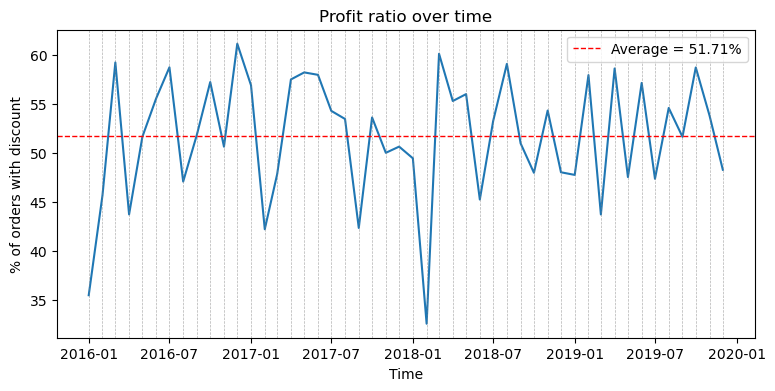

In [35]:
plt.figure(figsize=(9, 4))
chart = sb.lineplot(data=Disc_quota, x='Period_nt', y='pct_discount_orders')

for date in Disc_quota["Period_nt"]:
    plt.axvline(x=date, color="gray", linestyle="--", linewidth=0.5, alpha=0.6)

# Adding the line for calculating the median
avg = Disc_quota["pct_discount_orders"].mean()
plt.axhline(y=avg, color="red", linestyle="--", linewidth=1, label=f'Average = {avg:.2f}%')

chart.set_title('Profit ratio over time')
chart.set_xlabel('Time')
chart.set_ylabel('% of orders with discount')

plt.legend()
plt.show()

From this graph we can conclude that 51.71% of our orders have been given a discount. This insight is truly important, because it reveals that our company has been assigning excessive discounts, which can undermine the profit margin.

In order to easily compare them, we show the three previous graphs again in one window:

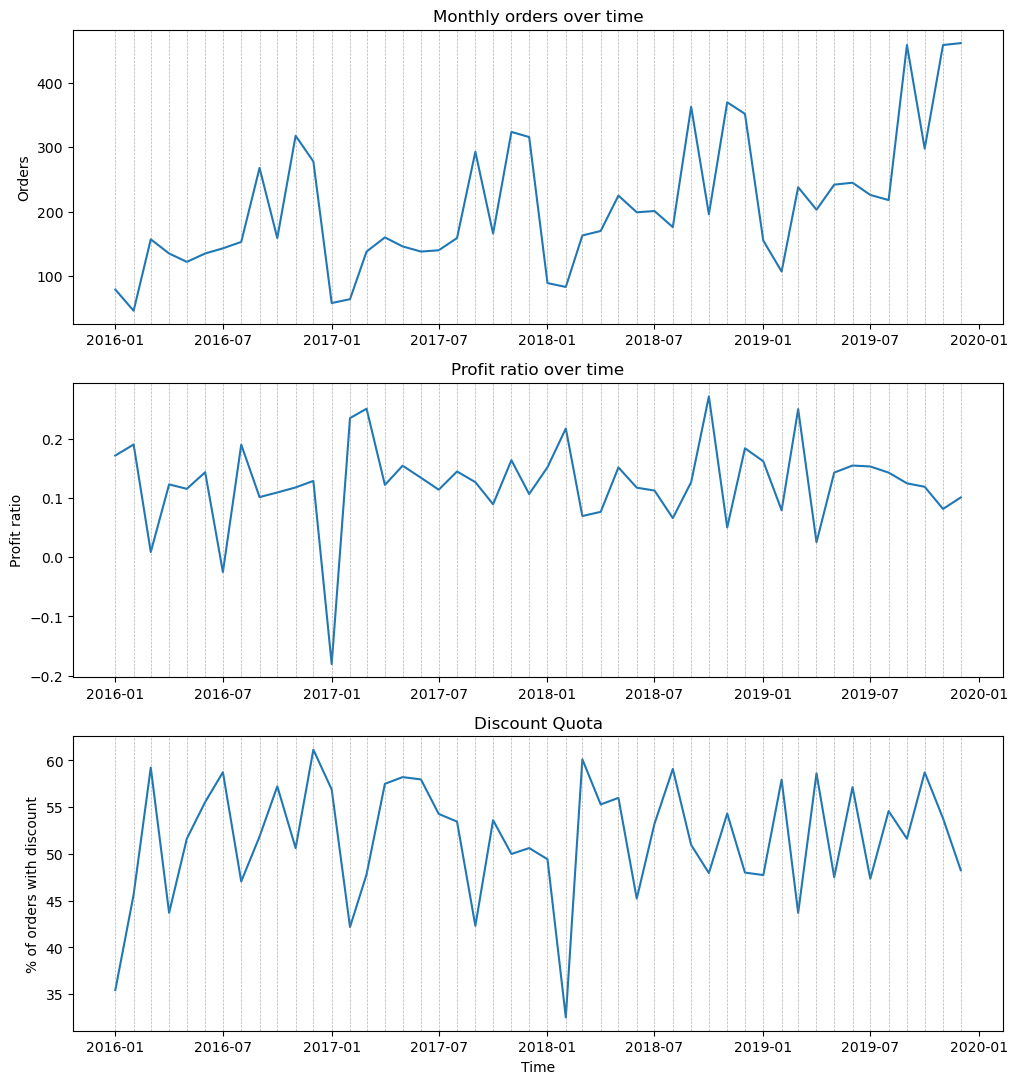

In [40]:
plt.figure( figsize = (12, 13))

plt.subplot(3,1,1)
chart=sb.lineplot(data=sales_months, x='Period_nt', y='Orders')

for date in sales_months["Period_nt"]:
    plt.axvline(x=date, color="gray", linestyle="--", linewidth=0.5, alpha=0.6)

    
chart.set_title('Monthly orders over time')
chart.set_xlabel('')
chart.set_ylabel('Orders')


plt.subplot(3,1,2)
chart=sb.lineplot(data=sales_months, x='Period_nt', y='Profit_Ratio')

for date in sales_months["Period_nt"]:
    plt.axvline(x=date, color="gray", linestyle="--", linewidth=0.5, alpha=0.6)

    
chart.set_title('Profit ratio over time')
chart.set_xlabel('')
chart.set_ylabel('Profit ratio')


plt.subplot(3,1,3)
chart=sb.lineplot(data=Disc_quota, x='Period_nt', y='pct_discount_orders')

for date in Disc_quota["Period_nt"]:
    plt.axvline(x=date, color="gray", linestyle="--", linewidth=0.5, alpha=0.6)

    
chart.set_title('Discount Quota')
chart.set_xlabel('Time')
chart.set_ylabel('% of orders with discount')

plt.show()

From comparing the three graphs, we conclude that the variables orders, profit ratio and discounts do not share a common behaviour over time.

#### **Mode of Shipment**

In [41]:
sales_regions = avg_profit_per_group("Ship Mode")

sales_regions

,Ship Mode,Orders,Sum_Profit,Sum_Sales,Profit_Ratio
0,First Class,1538,48969.8399,3.514284e+05,0.139345
1,Same Day,543,15891.7589,1.283631e+05,0.123803
2,Second Class,1945,57446.6354,4.591936e+05,0.125103
3,Standard Class,5968,164088.7875,1.358216e+06,0.120812


There is **no significant difference** in the profit ratio across the four shipment modes when it comes to the profit ratio per order.

#### **Order Segments**

In [42]:
sales_segments = avg_profit_per_group("Segment")
sales_segments

,Segment,Orders,Sum_Profit,Sum_Sales,Profit_Ratio
0,Consumer,5191,134119.2092,1.161401e+06,0.115481
1,Corporate,3020,91979.1340,7.061464e+05,0.130255
2,Home Office,1783,60298.6785,4.296531e+05,0.140343


There is a **noticable difference** between the different segments. Products of "Home Office" have a 30% higher profit on average, despite having the less amount of orders between the other groups.
This might show the current strategy of the company, which is massivelly selling the products to the "consumer" segment, while having a lower profit ratio. Whereas, the category "home office" with least orders charges a higher profit margin.

#### **Product Categories**

We will now look at the different product categories of our catalogue.

In [43]:
sales_categories = avg_profit_per_group("Category")

sales_categories

,Category,Orders,Sum_Profit,Sum_Sales,Profit_Ratio
0,Furniture,2121,18451.2728,741999.7953,0.024867
1,Office Supplies,6026,122490.8008,719047.0320,0.170352
2,Technology,1847,145454.9481,836154.0330,0.173957


The category "Furniture" is a significant outlier with a profit ratio near 0. To gain more insights, we will further look into the subcategories.

#### **Sub-Categories**

We start with the sub-category *"Furniture"*. For doing this, we first create a dataset only containing the sales of the Furniture Category.

In [57]:
sales_furniture = dataset[dataset["Category"] == "Furniture"]

sales_furniture_subs = sales_furniture.groupby("Sub-Category").agg(Orders = ("Order ID", "count"), Sum_Profit=("Profit", "sum"), Sum_Sales = ("Sales", "sum")).reset_index()
    
sales_furniture_subs["Profit_Ratio"] = sales_furniture_subs["Sum_Profit"]/sales_furniture_subs["Sum_Sales"]

sales_furniture_subs

,Sub-Category,Orders,Sum_Profit,Sum_Sales,Profit_Ratio
0,Bookcases,228,-3472.5560,114879.9963,-0.030228
1,Chairs,617,26590.1663,328449.1030,0.080957
2,Furnishings,957,13059.1436,91705.1640,0.142404
3,Tables,319,-17725.4811,206965.5320,-0.085645


We can see from our table, that the sub-categories "Bookcases" and "Tables" have a negative profit ratio. Therefore, we want to show the impact on our profit from these sub-categories.

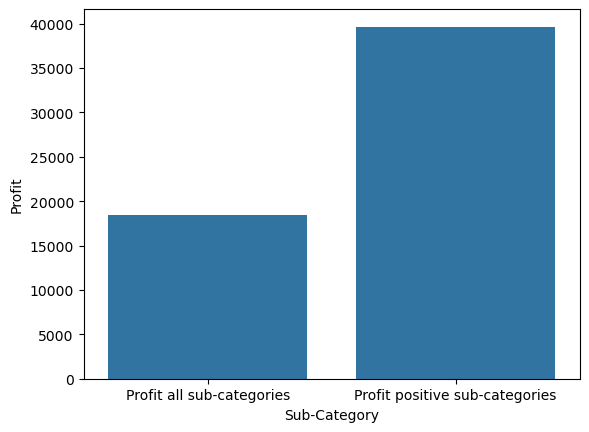

The sub-categories bookcases and tables create a loss of 21198.04 US-Dollar.


In [91]:
profit_all_furniture_subs = sales_furniture_subs.sum().Sum_Profit

profit_positive_furniture_subs = 0

for i in range(len(sales_furniture_subs)): # we run i for [:49] because there are 49 states
    if sales_furniture_subs["Sum_Profit"][i] >= 0:
        profit_positive_furniture_subs = profit_positive_furniture_subs + sales_furniture_subs["Sum_Profit"][i]

df_furniture_subs = pd.DataFrame({
    "Sub-Category": ["Profit all sub-categories", "Profit positive sub-categories"],
    "Profit": [profit_all_furniture_subs, profit_positive_furniture_subs]
})
#df_states

plt.show(sb.barplot(data = df_furniture_subs, x = "Sub-Category", y = "Profit"))

print("The sub-categories bookcases and tables create a loss of", round(profit_positive_furniture_subs -  profit_all_furniture_subs,2), "US-Dollar.")

We now look at the subcategories of *"Office Supplies"*. We start with creating a table that contains all the orders of that category to then group the orders by sub-categories.

In [63]:
sales_office = dataset[dataset["Category"] == "Office Supplies"]

sales_office_subs = sales_office.groupby("Sub-Category").agg(Orders = ("Order ID", "count"), Sum_Profit=("Profit", "sum"), Sum_Sales = ("Sales", "sum")).reset_index()
    
sales_office_subs["Profit_Ratio"] = sales_office_subs["Sum_Profit"]/sales_office_subs["Sum_Sales"]

sales_office_subs.sort_values(by = "Profit_Ratio", ascending = False).reset_index()

sales_office_subs

,Sub-Category,Orders,Sum_Profit,Sum_Sales,Profit_Ratio
0,Appliances,466,18138.0054,107532.161,0.168675
1,Art,796,6527.7870,27118.792,0.240711
2,Binders,1523,30221.7633,203412.733,0.148574
3,Envelopes,254,6964.1767,16476.402,0.422676
4,Fasteners,217,949.5182,3024.280,0.313965
5,Labels,364,5546.2540,12486.312,0.444187
6,Paper,1370,34053.5693,78479.206,0.433918
7,Storage,846,21278.8264,223843.608,0.095061
8,Supplies,190,-1189.0995,46673.538,-0.025477


There is a small gain in profit if we would stop selling products of the sub-category "Supplies". Our profit will rise by 1.189 US-Dollar.

We now look at the sub-categories of "Technology". We again start with creating a table that contains all the orders of that category to then group the orders by sub-categories.

In [64]:
sales_technology = dataset[dataset["Category"] == "Technology"]

sales_technology_subs = sales_technology.groupby("Sub-Category").agg(Orders = ("Order ID", "count"), Sum_Profit=("Profit", "sum"), Sum_Sales = ("Sales", "sum")).reset_index()
    
sales_technology_subs["Profit_Ratio"] = sales_technology_subs["Sum_Profit"]/sales_technology_subs["Sum_Sales"]

sales_technology_subs.sort_values(by = "Profit_Ratio", ascending = False).reset_index()

sales_technology_subs

,Sub-Category,Orders,Sum_Profit,Sum_Sales,Profit_Ratio
0,Accessories,775,41936.6357,167380.318,0.250547
1,Copiers,68,55617.8249,149528.030,0.371956
2,Machines,115,3384.7569,189238.631,0.017886
3,Phones,889,44515.7306,330007.054,0.134893


All the sub-categories have a positive profit-ratio, we will therefore not exclude any of them from our catalogue. However, we would recommend to understand more in detail the small profit radio of the sub-category "Machines", in order to improve profits of this items.

#### **Products**

In [75]:
sales_products = avg_profit_per_group("Product Name")

sales_products = sales_products.sort_values(by = "Sum_Profit", ascending = False).reset_index(drop=True)

sales_products.tail(15)

,Product Name,Orders,Sum_Profit,Sum_Sales,Profit_Ratio
1835,Bretford “Just In Time” Height-Adjustable Mult...,4,-964.1940,5634.900,-0.171111
1836,O'Sullivan 4-Shelf Bookcase in Odessa Pine,7,-975.0988,2740.197,-0.355850
1837,Hon 2090 “Pillow Soft” Series Mid Back Swivel/...,6,-989.0496,5282.424,-0.187234
1838,Epson TM-T88V Direct Thermal Printer - Monochr...,2,-1057.2300,1212.705,-0.871795
1839,"Riverside Furniture Oval Coffee Table, Oval En...",5,-1147.4000,4446.175,-0.258065
1840,BoxOffice By Design Rectangular and Half-Moon ...,3,-1148.4375,1706.250,-0.673077
1841,Balt Solid Wood Round Tables,4,-1201.0581,6518.754,-0.184247
1842,Martin Yale Chadless Opener Electric Letter Op...,6,-1299.1836,16656.200,-0.078000
1843,Cisco TelePresence System EX90 Videoconferenci...,1,-1811.0784,22638.480,-0.080000
1844,GBC DocuBind P400 Electric Binding System,6,-1878.1662,17965.068,-0.104545


From this table we found that there are several non profitable products. Therefore, we will create a bar plot to see how it affects our profitability.

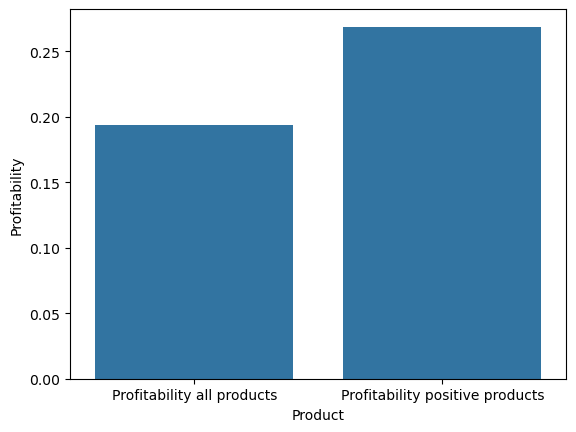

The products with a negative profitability create a loss of 38.54 % in profitability


In [94]:
profit_all_products = sales_products["Profit_Ratio"].mean()

profit_positive_products = 0

j = 0
for i in range(len(sales_products)):
    if sales_products["Profit_Ratio"][i] >= 0:
        profit_positive_products += sales_products["Profit_Ratio"][i]
        j = j+ 1
        
profit_positive_products = profit_positive_products/j

profit_positive_products
df_products = pd.DataFrame({
    "Product": ["Profitability all products", "Profitability positive products"],
    "Profitability": [profit_all_products, profit_positive_products]
})
df_products

plt.show(sb.barplot(data = df_products, x = "Product", y = "Profitability"))

print("The products with a negative profitability create a loss of", round(float((profit_positive_products-profit_all_products)/profit_all_products)*100, 2), "% in profitability") 

We will now investigate how that impacts our total profit.

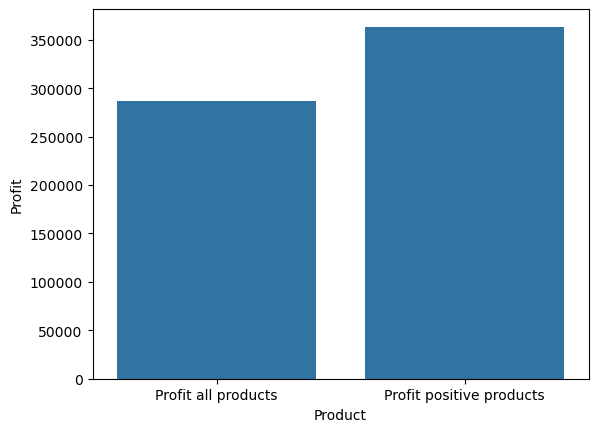

The products with a negative profitability create a profit loss of 77068.38 US-Dollar.


In [95]:
profit_all_products = sales_products.sum()["Sum_Profit"]

profit_positive_products = 0

for i in range(len(sales_products)):
    if sales_products["Sum_Profit"][i] >= 0:
        profit_positive_products += sales_products["Sum_Profit"][i]


df_products = pd.DataFrame({
    "Product": ["Profit all products", "Profit positive products"],
    "Profit": [profit_all_products, profit_positive_products]
})

plt.show(sb.barplot(data = df_products, x = "Product", y = "Profit"))

print("The products with a negative profitability create a profit loss of", round(profit_positive_products-profit_all_products, 2), "US-Dollar.")

In [98]:
products_to_analyze = sales_products[sales_products["Sum_Profit"] < 0]

products_to_analyze.head()

,Product Name,Orders,Sum_Profit,Sum_Sales,Profit_Ratio
1549,Global Super Steno Chair,7,-1.776357e-15,2389.902,-7.432760e-19
1550,Premier Electric Letter Opener,8,-7.105427e-15,2641.608,-2.689811e-18
1551,"Acco PRESSTEX Data Binder with Storage Hooks, ...",4,-1.614000e-01,62.946,-2.564103e-03
1552,Rubber Band Ball,4,-2.992000e-01,58.344,-5.128205e-03
1553,"Brites Rubber Bands, 1 1/2 oz. Box",3,-5.148000e-01,13.068,-3.939394e-02


In this list, we visualize the products that have a negative profit and need to be analyzed.

#### **State and Region**

We will look at the states and their regions simultaniously.

In [100]:
sales_states = dataset.groupby(["State","Region"]).agg(Orders = ("Order ID", "count"), Sum_Profit=("Profit", "sum"), Sum_Sales = ("Sales", "sum"))

sales_states["Profit_Ratio"] = sales_states["Sum_Profit"]/sales_states["Sum_Sales"]

sales_states = sales_states.sort_values(by = "Profit_Ratio", ascending = False).reset_index()

sales_states.tail(15)

,State,Region,Orders,Sum_Profit,Sum_Sales,Profit_Ratio
34,Nevada,West,39,3316.7659,16729.1020,0.198263
35,Idaho,West,21,826.7231,4382.4860,0.188642
36,California,West,2001,76381.3871,457687.6315,0.166885
37,West Virginia,East,4,185.9216,1209.8240,0.153677
38,Wyoming,West,1,100.1960,1603.1360,0.062500
39,Florida,South,383,-3399.3017,89473.7080,-0.037992
40,Oregon,West,124,-1190.4705,17431.1500,-0.068296
41,Arizona,West,224,-3427.9246,35282.0010,-0.097158
42,Pennsylvania,East,587,-15559.9603,116511.9140,-0.133548
43,North Carolina,South,249,-7490.9122,55603.1640,-0.134721


There are **substantial differences between the different states**, where the top 4 highest profitable states are Nevada, Idaho, California and West Virginia. However, we can not tell if there are systematical differences between the regions as a whole. Therefore, we will explore the regions by themself in order identify possible regions to exclude from our service.

In [101]:
sales_region = avg_profit_per_group("Region")

sales_region

,Region,Orders,Sum_Profit,Sum_Sales,Profit_Ratio
0,Central,2323,39706.3625,501239.8908,0.079216
1,East,2848,91522.7800,678781.2400,0.134834
2,South,1620,46749.4303,391721.9050,0.119343
3,West,3203,108418.4489,725457.8245,0.149448


There are some clearly visible differences between the regions. Nevertheless, all of them are profitable. For this reason **advices** on reducing our area of operation must be **considered on a state level**. 

To get an idea of the impact the ratio negative states have on our profitability, we will create a diagramm comparig our profitability with- and without the negative states.

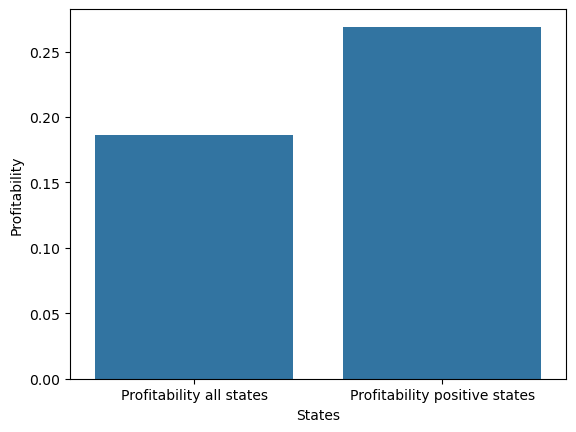

The states with a negative profitability create a loss of 44.59 %.


In [108]:
profit_all_states = sales_states["Profit_Ratio"].mean()

profit_positive_states = 0

j = 0
for i in range(len(sales_states)):
    if sales_states["Profit_Ratio"][i] >= 0:
        profit_positive_states += sales_states["Profit_Ratio"][i]
        j = j+ 1
        
profit_positive_states = profit_positive_states/j

profit_positive_states
df_states = pd.DataFrame({
    "States": ["Profitability all states", "Profitability positive states"],
    "Profitability": [profit_all_states, profit_positive_states]
})
df_states

plt.show(sb.barplot(data = df_states, x = "States", y = "Profitability"))

print("The states with a negative profitability create a loss of", round(float((profit_positive_states-profit_all_states)/profit_all_states)*100, 2), "%.")

We will now explore how that impacts our total profit.

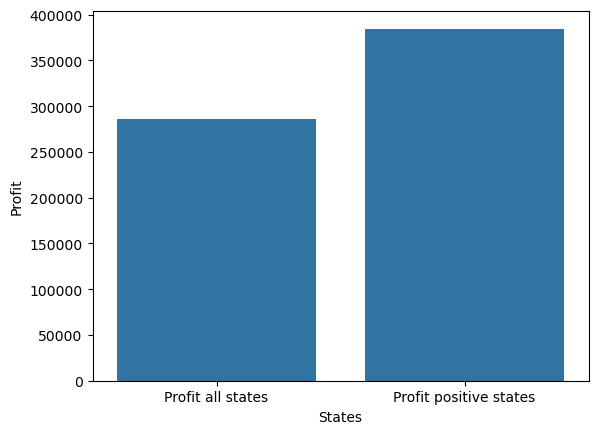

The states with a negative profit create a loss of 98246.74 US-Dollar.


In [109]:
profit_all_states = sales_states.sum().Sum_Profit

profit_positive_states = 0

for i in range(len(sales_states)): # we run i for [:49] because there are 49 states
    if sales_states["Sum_Profit"][i] >= 0:
        profit_positive_states = profit_positive_states + sales_states["Sum_Profit"][i]

df_states = pd.DataFrame({
    "States": ["Profit all states", "Profit positive states"],
    "Profit": [profit_all_states, profit_positive_states]
})
df_states

plt.show(sb.barplot(data = df_states, x = "States", y = "Profit"))

print("The states with a negative profit create a loss of", round(float(profit_positive_states -  profit_all_states),2), "US-Dollar.")

In the following list, we visualize the states that have a negative profit and need to be analyzed.

In [113]:
states_to_analyze = sales_states[["State","Sum_Profit"]] #["Sum_Profit"] < 0

states_to_analyze = states_to_analyze[states_to_analyze["Sum_Profit"] < 0].sort_values(by = "Sum_Profit").reset_index(drop = True)

states_to_analyze

,State,Sum_Profit
0,Texas,-25729.3563
1,Ohio,-16971.3766
2,Pennsylvania,-15559.9603
3,Illinois,-12607.8870
4,North Carolina,-7490.9122
5,Colorado,-6527.8579
6,Tennessee,-5341.6936
7,Arizona,-3427.9246
8,Florida,-3399.3017
9,Oregon,-1190.4705


# Customer Analysis

For this part of the analysis, we want to find the most **profitable customers**. Therefore, in the following table, we will visualize the profitability of the customers according to their profit ratios.

In [124]:
customers_profitable=dataset.groupby("Customer ID").agg(Orders = ("Order ID", "count"), Sum_Profit=("Profit", "sum"), Sum_Sales = ("Sales", "sum")).reset_index()

customers_profitable["Profit Ratio"] = (customers_profitable["Sum_Profit"]/customers_profitable["Sum_Sales"])

customers_profitable = customers_profitable.sort_values(by="Profit Ratio", ascending= False).reset_index(drop=True)

customers_profitable

,Customer ID,Orders,Sum_Profit,Sum_Sales,Profit Ratio
0,JC-15385,4,502.9244,1058.108,0.475305
1,TC-20980,12,8981.3239,19052.218,0.471406
2,RB-19360,18,6976.0959,15117.339,0.461463
3,SR-20740,12,1990.4244,4345.886,0.458002
4,BO-11425,2,59.4522,130.830,0.454423
...,...,...,...,...,...
788,HG-14965,17,-2797.9635,3247.642,-0.861537
789,LF-17185,16,-3583.9770,3930.509,-0.911835
790,NC-18415,14,-2204.8072,2218.990,-0.993608
791,SR-20425,9,-3333.9144,3233.481,-1.031060


With this first impression, we can observe that there are customers that have a high negative profit ratio. For this reason, we want to explore how many of them are, so our sales team can explore in deep the reasons with each customer.

In [160]:
customers_not_profit=customers_profitable[customers_profitable["Profit Ratio"]<0]

customers_not_profit = customers_not_profit.sort_values(by="Profit Ratio", ascending=True).reset_index(drop=True)

customers_not_profit

,Customer ID,Orders,Sum_Profit,Sum_Sales,Profit Ratio
0,CS-12505,9,-6626.3895,5690.055,-1.164556
1,SR-20425,9,-3333.9144,3233.481,-1.031060
2,NC-18415,14,-2204.8072,2218.990,-0.993608
3,LF-17185,16,-3583.9770,3930.509,-0.911835
4,HG-14965,17,-2797.9635,3247.642,-0.861537
...,...,...,...,...,...
150,BS-11380,13,-17.5322,3887.834,-0.004510
151,ON-18715,15,-5.8890,1567.520,-0.003757
152,MD-17860,8,-4.0403,1204.910,-0.003353
153,PL-18925,8,-0.7527,239.481,-0.003143


In [175]:
print("The total number of customers with a negative profitability is ", len(customers_not_profit), "out ouf ",len(customers_profitable),"customers in total.")
print("This represents a", round(len(customers_not_profit)/len(customers_profitable),2)*100, "% from the total customer base.")

The total number of customers with a negative profitability is  155 out ouf  793 customers in total.
This represents a 20.0 % from the total customer base.


In [176]:
sum_negative_profit = customers_not_profit["Sum_Sales"].sum()
print("The total loss generated by the customers with negative profitability is ", round(sum_negative_profit,2),"USD.")

The total loss generated by the customers with negative profitability is  391950.41 USD.


**Average Order Value**

Now, we want to explore the **average order value**.This indicator can be calculated dividing the total profit with the total number of orders.

In [136]:
average_order_value = dataset.groupby("Customer ID").agg(Total_Orders = ("Order ID", "count"), Sum_Profit=("Profit", "sum")).reset_index()

average_order_value ["Average_Order_Value"] = (average_order_value["Sum_Profit"]/average_order_value["Total_Orders"])

average_order_value = average_order_value.sort_values(by="Average_Order_Value", ascending= False).reset_index(drop=True)

average_order_value

,Customer ID,Total_Orders,Sum_Profit,Average_Order_Value
0,TC-20980,12,8981.3239,748.443658
1,MW-18235,3,1665.5160,555.172000
2,HL-15040,11,5622.4292,511.129927
3,TA-21385,10,4703.7883,470.378830
4,CM-12385,10,3899.8904,389.989040
...,...,...,...,...
788,JR-15670,3,-785.1645,-261.721500
789,PK-18910,3,-798.7050,-266.235000
790,SR-20425,9,-3333.9144,-370.434933
791,GT-14635,6,-4108.6589,-684.776483


As an important insight, we can find that there are customers with a high average order value, which helps to optimize pricing and upselling/cross-selling strategies. It is important to mention that the customers can place an order coming from a different location. 

**Churn Rate**

In [139]:
dataset["Order Date"] = pd.to_datetime(dataset["Order Date"]) #we ensure the date column is in datetime format.
dataset["Order Period"] = dataset["Order Date"].dt.to_period("M") #extract the period to months
customer_period = dataset.groupby("Order Period")["Customer ID"].nunique() #get a unique list of customers active in each period

We also want to know the last month of purchase, which would be considered the "current month of purchase" for the future calculation of the churn rate.

In [140]:
last_month_purchase=dataset["Order Period"].max()
last_month_purchase

Period('2019-12', 'M')

In this case, we found that the last ordered month or the current period is 2019-12 or December 2019. This date will be our reference date for the analysis.

In [141]:
current_period = pd.Period("2019-12", freq="M")

Now we calculate the last purchase of the clients, grouped by the order period. For example, customer "XP-21865" made his last purchased on 2016-01 (January of 2016)

In [142]:
last_purchase = dataset.groupby("Order Period")["Customer ID"].max().reset_index()

For a month-to-month Churn Rate, we define a function in the following lines of code:

In [144]:
def calculate_monthly_churn(df, current_period):
    previous_period = current_period-1
    # Get all customers who were active up to the previous period
    customers_at_start = df[df["Order Period"]==previous_period]["Customer ID"].unique()
    # Get all customers who were active *in* the current period
    customers_at_end = df[df["Order Period"] == current_period]["Customer ID"].unique()    
    # Get Churned Customers: Those active at the start but not active at the end
    churned_customers = len(set(customers_at_start)-set(customers_at_end))
    # Starting Customers: Those active in the previous period
    starting_customers = len(customers_at_start)
    return churned_customers, starting_customers

In [145]:
#month to analyze: December, 2019 or "2019-12"
month_to_analyze = pd.Period("2019-12", freq= "M")

In [146]:
churned_customers, starting_customers = calculate_monthly_churn(dataset, month_to_analyze)

In [147]:
churn_rate = (churned_customers / starting_customers) * 100

In [148]:
print(f"Clients at start: {starting_customers}")
print(f"Churned Clients: {churned_customers}")
print(f"Churn Rate: {churn_rate:.2f}%")

Clients at start: 216
Churned Clients: 162
Churn Rate: 75.00%


We can also create a new a loop, in order to find the churn rate for every month.

In [149]:
all_periods=sorted(dataset["Order Period"].unique())
churn_results=[] #empty list to save the results of the loop
for i in range(1,len(all_periods)):
    current_period = all_periods[i]
    churned, base = calculate_monthly_churn(dataset, current_period)
    if base > 0:
        churn_rate = (churned/base)*100
    else:
        churn_rate = 0.0
    churn_results.append({
        "Period": current_period,
        "Clients_Base (t-1)": base,
        "Clients_Lost": churned,
        "Churn_Rate": churn_rate
    })
churn_rate_df = pd.DataFrame(churn_results)


In [151]:
churn_rate_df.head(15)

,Period,Clients_Base (t-1),Clients_Lost,Churn_Rate
0,2016-02,32,29,90.625000
1,2016-03,27,23,85.185185
2,2016-04,69,65,94.202899
3,2016-05,64,58,90.625000
4,2016-06,67,62,92.537313
5,2016-07,63,59,93.650794
6,2016-08,65,58,89.230769
7,2016-09,70,60,85.714286
8,2016-10,118,104,88.135593
9,2016-11,75,66,88.000000


In [233]:
print("The calculated monthly churn rates consistently ranges between", round(min(churn_rate_df["Churn_Rate"]),2),"%", "and", round(max(churn_rate_df["Churn_Rate"]),2), "% which reveals an extremely high level of customer churn per month.")

The calculated monthly churn rates consistently ranges between 72.12 % and 97.83 % reveal an extremely high level of customer churn per month.


#### Month-Year Churn Rate (YOY)

For the yearly churned rate we first define the function for calculating the annual churn, in month-year period format.

In [189]:
def calculate_annual_churn (df, previous_period, current_period):
    clients_before = df[df["Order Month-Year"] == previous_period]["Customer ID"].unique()
    clients_actual = df[df["Order Month-Year"] == current_period]["Customer ID"].unique()
    base_clients = len(clients_before)
    churned_clients = set(clients_before)-set(clients_actual)
    churned = len(churned_clients)
    return churned, base_clients

We transform the column "Order Date" into a "Order Month-Year":

In [192]:
dataset["Order Date"] = pd.to_datetime(dataset["Order Date"] )
dataset["Order Month-Year"] = dataset["Order Date"].dt.strftime("%Y-%m")

# to delete rows with null dates that could not be converted
dataset.dropna(subset=["Order Month-Year", "Customer ID"], inplace=True)

And now we calculate the loop to create the loop where we will execute our function.

In [195]:
all_periods = sorted(dataset["Order Month-Year"].unique())
churn_results_yoy = [] # List to store annual churn results
periods_to_skip = 12
for i in range(periods_to_skip, len(all_periods)):
    current_period = all_periods[i]
    previous_period = all_periods[i-periods_to_skip]
    if current_period.split('-')[1] == previous_period.split('-')[1]:
        churned, base_clients = calculate_annual_churn(dataset, previous_period, current_period)
        if base_clients > 0:
            churn_rate = (churned / base_clients) * 100
        else:
            churn_rate = 0.0
            
        churn_results_yoy.append({
            "Period": current_period,
            "Base_Period (t-12)": previous_period,
            "Clients_Base (t-12)": base_clients,
            "Clients_Lost (YOY)": churned,
            "Annual_Churn_Rate (%)": churn_rate
        })

In [201]:
#To create the final dataframe:
annual_churn_rate_yoy_df = pd.DataFrame(churn_results_yoy)

In [202]:
annual_churn_rate_yoy_df

,Period,Base_Period (t-12),Clients_Base (t-12),Clients_Lost (YOY),Annual_Churn_Rate (%)
0,2017-01,2016-01,32,29,90.625000
1,2017-02,2016-02,27,27,100.000000
2,2017-03,2016-03,69,62,89.855072
3,2017-04,2016-04,64,55,85.937500
4,2017-05,2016-05,67,65,97.014925
5,2017-06,2016-06,63,58,92.063492
6,2017-07,2016-07,65,58,89.230769
7,2017-08,2016-08,70,67,95.714286
8,2017-09,2016-09,118,103,87.288136
9,2017-10,2016-10,75,71,94.666667


For a further analysis, we include a trend line to analyze the behaviour of the churn rate across the whole period (2016 to 2019).

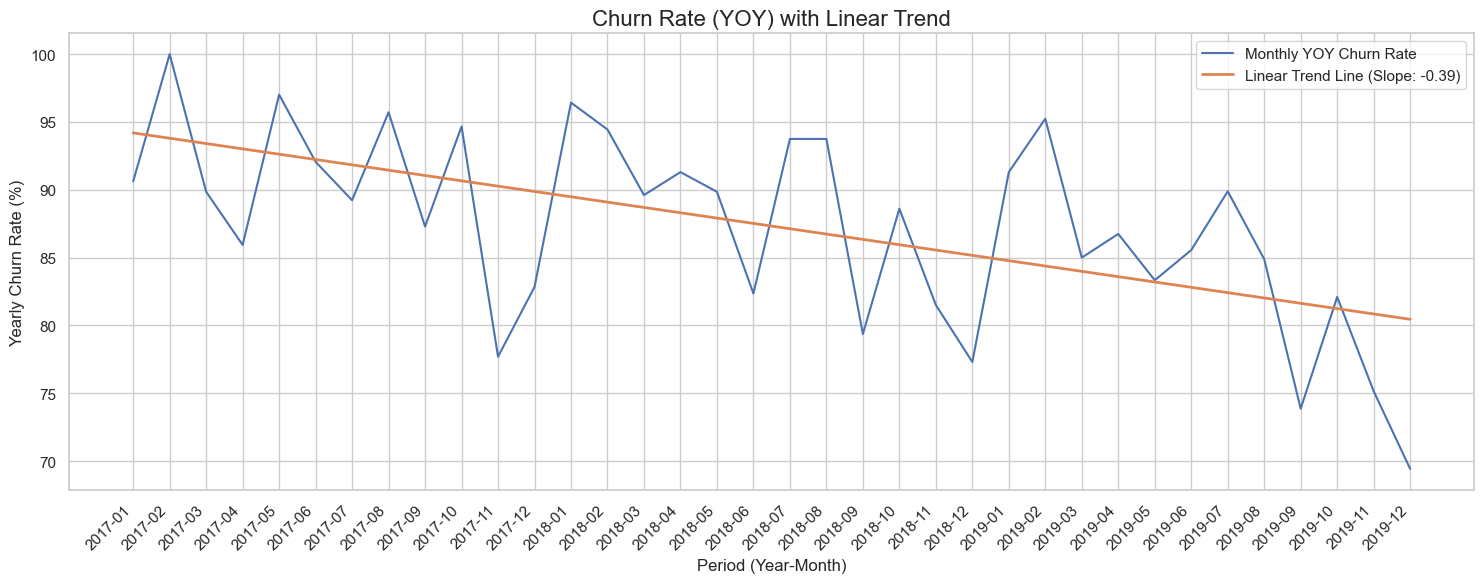

In [230]:
import numpy as np
# We convert "Period" (e.g., "2017-01") into a numerical value (index) for regression
# We create a simple numerical sequence representing the months
annual_churn_rate_yoy_df["Month_Index"] = np.arange(len(annual_churn_rate_yoy_df))

# Then we calculate the linear trend line using NumPy's polyfit
# x = Month_Index, y = Annual_Churn_Rate (%)
z = np.polyfit(
    annual_churn_rate_yoy_df['Month_Index'], 
    annual_churn_rate_yoy_df['Annual_Churn_Rate (%)'], 
    1
)
# Create a polynomial function from the calculated coefficients (slope 'm' and intercept 'b')
p = np.poly1d(z)

# Setup and Plotting
sb.set_theme(style="whitegrid")
plt.figure(figsize=(15, 6))

# Plot the main YOY Churn Rate line
sb.lineplot(
    data=annual_churn_rate_yoy_df,
    x="Period", 
    y="Annual_Churn_Rate (%)",
    label="Monthly YOY Churn Rate"
)

# We add the Trend Line and plot the calculated trend line using the polynomial function 'p'
plt.plot(
    annual_churn_rate_yoy_df["Period"], # Use the original Period values for the x-axis
    p(annual_churn_rate_yoy_df['Month_Index']), # Calculate the y-values using the trend function 'p' 
    linestyle='-',
    linewidth=2,
    label=f'Linear Trend Line (Slope: {z[0]:.2f})'
)

plt.title("Churn Rate (YOY) with Linear Trend", fontsize=16)
plt.xlabel("Period (Year-Month)", fontsize=12)
plt.ylabel("Yearly Churn Rate (%)", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(loc='upper right')
plt.tight_layout()

plt.show()

The YOY Churn Rate remains critically high (mostly above 80%), but the Linear Trend Line (Slope: -0.39) indicates that customer retention has been slowly improving over the three-year period, despite high monthly volatility which potentially shows seasonal effects.

In [237]:
print("The calculated YOY churn rates consistently range between", round(min(annual_churn_rate_yoy_df["Annual_Churn_Rate (%)"]),2),"%", "and", round(max(annual_churn_rate_yoy_df["Annual_Churn_Rate (%)"]),2), "%, which reveals an extremely high level of customer churn during this period.")

The calculated YOY churn rates consistently range between 69.43 % and 100.0 %, which reveals an extremely high level of customer churn during this period.


# Conclusion

**Final Conclusions and Strategic Recommendations**

The analysis of profitability and customer behavior reveals clear areas of opportunity that require immediate action (to correct losses) and strategic reinforcement (to scale successes).

**1. Product Category and Sub-Categories**

| Category | Status | Key Recommendation |
| :--- | :--- | :--- |
| **Technology** | **High Performance** | The only category with **positive profitability across all subcategories**. | 
| **Furniture** | **Critical Losses** | Subcategories **"Bookcases"** and **"Tables"** report **significant negative profitability**. The profit loss reaches aprox. 21,200 USD. | 
| **Office Supplies** | **Specific Loss** | The **"Supplies"** subcategory shows a specific loss of **$1,189 USD**. | 

Recommendations for each sector:
- *Technology*: **Growth Strategy:** Prioritize investment in inventory and marketing for Technology. Identify and **replicate the operational and pricing best practices** from this category across the rest of the portfolio.
- *Furniture*: **Critical and Immediate Action (Cost & Pricing):** Launch a cost audit for the sub-categories "Bookcases" and "Tables". This must include **supplier renegotiation**, **price adjustments**, and, if losses persist, considering the **elimination of non-essential SKUs**.
- *Office supplies*: **Immediate Review:** Analyze whether this loss is caused by operational errors or excessive discounting before implementing drastic measures. |


**2. Customer Segment Optimization**

The segmentation analysis highlights an opportunity to maximize profitability without depending on total order volume:

- Highest Value Segment: The "Home Office" segment is the company's most profitable, despite not having the highest order volume. This indicates that products sold to these customers carry a superior profit margin.

- Recommendation: Create a premium value strategy focused on this segment. We suggest implementing a VIP program with personalized offers, high-end product bundles, and exclusive features (e.g., priority shipping or dedicated customer support) to secure loyalty and maximize the value of each order.

**3. Geography and Root Cause Analysis (RCA)**

Despite finding that the Regions do not indicate regional profit losses, we broke down the analysis into a state level. There we found that the overall profitability is being dragged down by poor performance in certain locations:

- Negative Impact: There are specific States which exert a substantial negative impact on the company's general profitability, such as **Texas, Ohio, Pennsylvania, Illinois, North Carolina, and Colorado**.
- Recommendation: Headquarters should establish a Root Cause Analysis (RCA) task force with the store managers located in these states to identify the source of the problems. Potential causes to investigate include: high shipping/logistics costs, aggressive local pricing competition, or team training issues. If these problems cannot be solved, we could consider reducing the company's presence in those states.

**4. Discount Control**

There is a direct correlation between the current discount policy and the high rate of customer abandonment:
- Discount Risk: $51.71\%$ of all orders include some form of discount, which is eroding profitability.
- Pricing Policy Recommendation: Discounts must be applied strategically, not universally. We advise restricting offers to clients with a High Average Order Value (AOV), using them as a loyalty tool rather than a low-margin acquisition tool.


**5. Retention (Churn Rate)**

- Retention Problem (Churn): The higher monthly churn rate (72 % - 98 %) and the Year-Over-Year churn rate (69 % - 100 %) confirm a loyalty issue. Customers are not purchasing frequently leaving the company heavily reliant on acquiring new customers. However, the Linear Trend Line (with a negative slope) indicates that customer retention has been slowly improving over the three-year period, despite high monthly volatility which potentially shows seasonal effects.
- Fidelity Recommendation: Implement a rewards and loyalty program that offers continuous value, for example a loyalty card, where the clients can enjoy benefits based on their loyalty.